# Concealed Weapon Detection (CWD)

Build and evaluate the PMMW gun-detection component.

## Planned workflow

1. Clean and inspect the data
2. Create leakage-safe splits
3. Convert labels to YOLO format
4. Train and evaluate lightweight detectors
5. Select the final CWD model

## 1. Dataset setup and parsing

Parse the Pascal VOC XML files into image and annotation DataFrames.

In [1]:
from pathlib import Path
import hashlib
import filecmp
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

SEED = 42
DATASET_ROOT = Path("pmmw-dataset")

IMAGE_DIR = DATASET_ROOT / "images"
ANNOTATION_DIR = DATASET_ROOT / "Annotations"

if not IMAGE_DIR.exists() or not ANNOTATION_DIR.exists():
    raise FileNotFoundError(f"PMMW dataset not found at {DATASET_ROOT.resolve()}")

In [2]:
image_paths = sorted(IMAGE_DIR.glob("*.jpg"))
xml_paths = sorted(ANNOTATION_DIR.glob("*.xml"))
records = []

for xml_path in xml_paths:
    root = ET.parse(xml_path).getroot()
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    for obj in root.findall("object"):
        box = obj.find("bndbox")
        xmin, ymin, xmax, ymax = [
            int(box.findtext(name)) for name in ("xmin", "ymin", "xmax", "ymax")
        ]
        records.append({
            "image_name": f"{xml_path.stem}.jpg",
            "class_name": obj.findtext("name").strip().lower(),
            "width": width, "height": height,
            "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax,
        })

annotations = pd.DataFrame(records)
annotations["box_width"] = annotations["xmax"] - annotations["xmin"]
annotations["box_height"] = annotations["ymax"] - annotations["ymin"]
annotations["relative_box_area"] = (
    annotations["box_width"] * annotations["box_height"]
    / (annotations["width"] * annotations["height"])
)
annotations["invalid_box"] = (
    (annotations["xmin"] < 0) | (annotations["ymin"] < 0)
    | (annotations["xmax"] > annotations["width"])
    | (annotations["ymax"] > annotations["height"])
    | (annotations["box_width"] <= 0) | (annotations["box_height"] <= 0)
)

per_image = annotations.groupby("image_name").agg(
    object_count=("class_name", "size"),
    classes=("class_name", lambda values: ", ".join(sorted(set(values)))),
    has_gun=("class_name", lambda values: "gun" in set(values)),
).reset_index()

images = pd.DataFrame({
    "image_name": [path.name for path in image_paths],
    "image_path": image_paths,
}).merge(per_image, on="image_name", how="left")
images["has_annotation"] = images["object_count"].notna()
images["object_count"] = images["object_count"].fillna(0).astype(int)
images["has_gun"] = images["has_gun"].fillna(False).astype(bool)

C:\Users\ADAM-\AppData\Local\Temp\ipykernel_548\168049619.py:48: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  images["has_gun"] = images["has_gun"].fillna(False).astype(bool)


## 2. Dataset statistics

In [3]:
image_names = {path.stem for path in image_paths}
xml_names = {path.stem for path in xml_paths}
missing_xml = sorted(image_names - xml_names)
missing_images = sorted(xml_names - image_names)
annotated_images = images[images["has_annotation"]]

print(f"Image files:             {len(image_paths):,}")
print(f"XML annotation files:    {len(xml_paths):,}")
print(f"Total bounding boxes:    {len(annotations):,}")
print(f"Gun-positive images:     {annotated_images['has_gun'].sum():,}")
print(f"Gun-negative images:     {(~annotated_images['has_gun']).sum():,}")
print(f"Images without XML:      {len(missing_xml):,}")
print(f"XML files without image: {len(missing_images):,}")
print(f"Invalid bounding boxes:  {annotations['invalid_box'].sum():,}")
print(f"Image dimensions:        {sorted(set(zip(annotations.width, annotations.height)))}")

if missing_xml:
    print("\nImages without annotations:", ", ".join(missing_xml))

Image files:             1,624
XML annotation files:    1,618
Total bounding boxes:    2,445
Gun-positive images:     833
Gun-negative images:     785
Images without XML:      6
XML files without image: 0
Invalid bounding boxes:  0
Image dimensions:        [(284, 631), (286, 635)]

Images without annotations: image_0105, image_0417, image_0419, image_0492, image_1060, image_1468


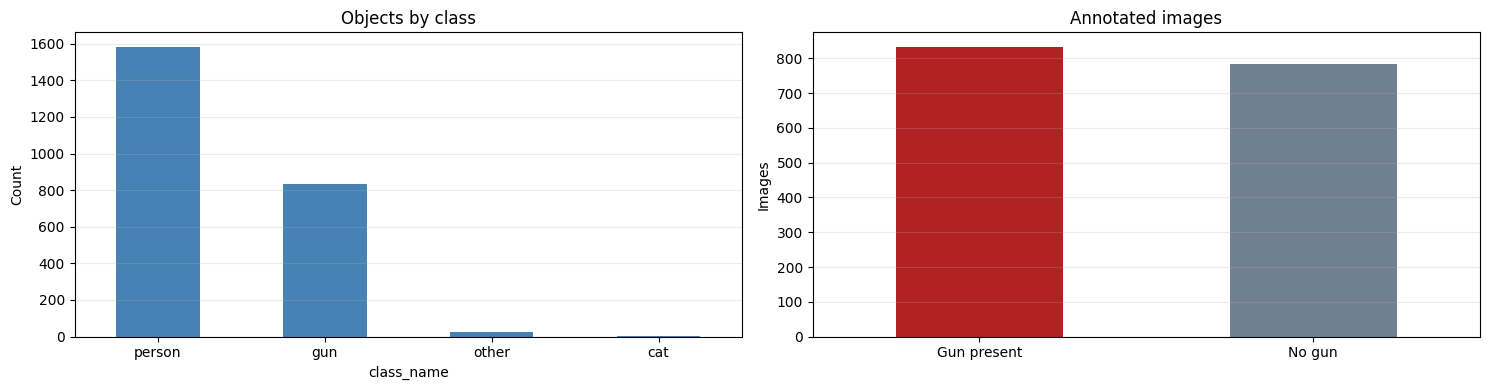

In [4]:
class_counts = annotations["class_name"].value_counts().sort_values(ascending=False)
gun_status = pd.Series({
    "Gun present": int(annotated_images["has_gun"].sum()),
    "No gun": int((~annotated_images["has_gun"]).sum()),
})
boxes_per_image = annotated_images["object_count"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
class_counts.plot.bar(ax=axes[0], color="steelblue", title="Objects by class")
gun_status.plot.bar(ax=axes[1], color=["firebrick", "slategray"], title="Annotated images")
axes[0].set_ylabel("Count")
axes[1].set_ylabel("Images")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Annotation examples

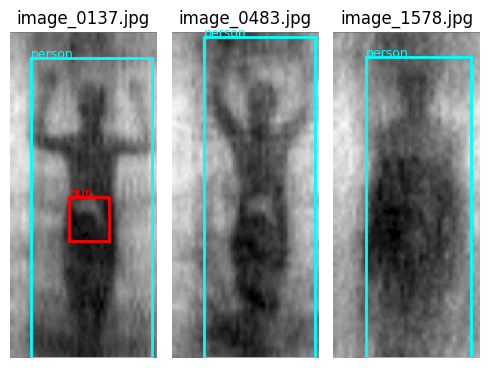

In [5]:
sample_names = annotated_images.sample(3, random_state=SEED)["image_name"]
colours = {"gun": "red", "person": "cyan", "other": "orange", "cat": "yellow"}
fig, axes = plt.subplots(1, 3, figsize=(5, 5))

for ax, image_name in zip(axes.flat, sample_names):
    ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
    for _, box in annotations[annotations["image_name"] == image_name].iterrows():
        colour = colours.get(box["class_name"], "lime")
        ax.add_patch(Rectangle(
            (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9)
    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Exact duplicate detection

Use SHA-256 and byte comparison to find exact copies only.

In [6]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

images["sha256"] = images["image_path"].apply(sha256_file)
duplicate_groups = images.groupby("sha256")["image_path"].apply(list)
duplicate_groups = duplicate_groups[duplicate_groups.apply(len) > 1]

# Confirm every hash match by comparing the complete file contents.
for paths in duplicate_groups:
    if not all(filecmp.cmp(paths[0], path, shallow=False) for path in paths[1:]):
        raise RuntimeError("A hash group failed byte-for-byte verification.")

duplicate_files = sum(len(paths) for paths in duplicate_groups)
extra_copies = sum(len(paths) - 1 for paths in duplicate_groups)

print("Duplicate method: SHA-256 + byte-for-byte verification")
print(f"Exact duplicate groups:  {len(duplicate_groups):,}")
print(f"Files in those groups:   {duplicate_files:,}")
print(f"Extra duplicate copies:  {extra_copies:,}")
print(f"Unique image contents:   {images['sha256'].nunique():,}")
print("Verification:            all duplicate groups are byte-identical")

print("\nExample duplicate groups:")
for paths in duplicate_groups.head(5):
    print("  " + ", ".join(path.name for path in paths))

Duplicate method: SHA-256 + byte-for-byte verification
Exact duplicate groups:  305
Files in those groups:   736
Extra duplicate copies:  431
Unique image contents:   1,193
Verification:            all duplicate groups are byte-identical

Example duplicate groups:
  image_0243.jpg, image_0249.jpg
  image_0935.jpg, image_0937.jpg
  image_1030.jpg, image_1031.jpg
  image_0467.jpg, image_0475.jpg
  image_0730.jpg, image_1123.jpg


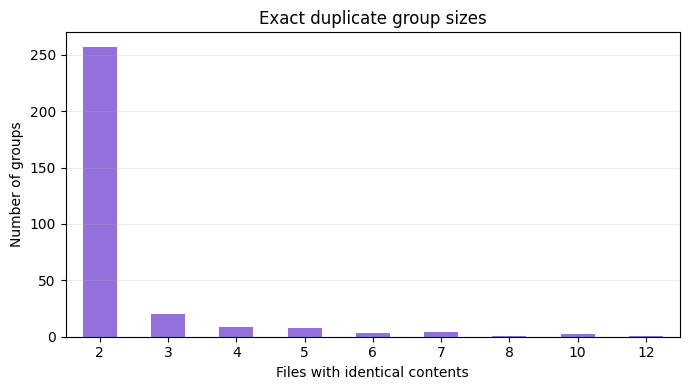

In [7]:
group_sizes = duplicate_groups.apply(len).value_counts().sort_index()
ax = group_sizes.plot.bar(figsize=(7, 4), color="mediumpurple")
ax.set(title="Exact duplicate group sizes", xlabel="Files with identical contents", ylabel="Number of groups")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

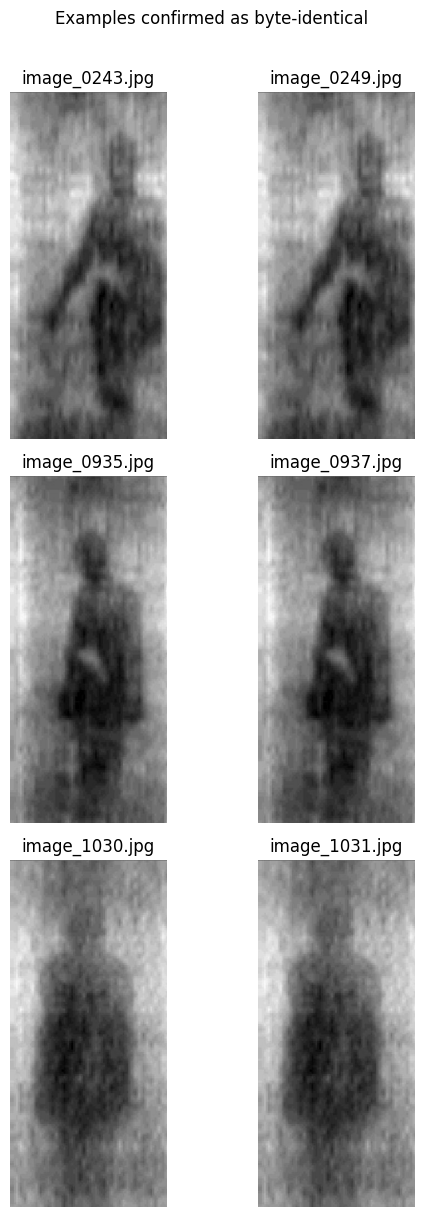

In [8]:
examples = duplicate_groups.head(3).tolist()
if examples:
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 4 * len(examples)))
    if len(examples) == 1:
        axes = [axes]
    for row, paths in zip(axes, examples):
        for ax, path in zip(row, paths[:2]):
            ax.imshow(Image.open(path), cmap="gray")
            ax.set_title(path.name)
            ax.axis("off")
    fig.suptitle("Examples confirmed as byte-identical", y=1.01)
    plt.tight_layout()
    plt.show()

## 5. Remove exact duplicates from the working dataset

Create `clean_images` and `clean_annotations` by removing duplicate copies, noise images, gun-label conflicts and `cat`/`other` images.

In [9]:
# Find conflicts among exact duplicates.
duplicate_rows = images[images["sha256"].isin(duplicate_groups.index) & images["has_annotation"]]
gun_label_counts = duplicate_rows.groupby("sha256")["has_gun"].nunique()
gun_conflict_hashes = set(gun_label_counts[gun_label_counts > 1].index)

# Keep the best copy from each duplicate group.
representatives = (
    images.sort_values(
        ["has_annotation", "has_gun", "object_count", "image_name"],
        ascending=[False, False, False, True],
    )
    .drop_duplicates("sha256")
    .sort_values("image_name")
    .reset_index(drop=True)
)

kept_names = set(representatives["image_name"])
kept_by_hash = representatives.set_index("sha256")["image_name"]
duplicate_manifest = images[~images["image_name"].isin(kept_names)].copy()
duplicate_manifest["kept_image_name"] = duplicate_manifest["sha256"].map(kept_by_hash)
duplicate_manifest = duplicate_manifest[["image_name", "kept_image_name", "sha256"]]

unannotated_noise = {
    "image_0105.jpg", "image_0417.jpg", "image_0419.jpg",
    "image_0492.jpg", "image_1060.jpg", "image_1468.jpg",
}

# Build the exclusion lists.
removed_noise = sorted(unannotated_noise & kept_names)
removed_conflicts = sorted(
    representatives.loc[representatives["sha256"].isin(gun_conflict_hashes), "image_name"]
)
unusual_class_names = set(
    annotations.loc[annotations["class_name"].isin(["cat", "other"]), "image_name"]
)
removed_unusual = sorted(
    (unusual_class_names & kept_names) - set(removed_noise) - set(removed_conflicts)
)

excluded_names = set(removed_noise + removed_conflicts + removed_unusual)
clean_images = representatives[~representatives["image_name"].isin(excluded_names)].copy().reset_index(drop=True)
clean_names = set(clean_images["image_name"])
clean_annotations = annotations[annotations["image_name"].isin(clean_names)].copy().reset_index(drop=True)

print(f"Clean images: {len(clean_images)}")
print(f"Clean annotations: {len(clean_annotations)}")

Clean images: 1132
Clean annotations: 1725


## 6. Review gun-label disagreements

Review the excluded gun-label conflicts. Change `REVIEW_PAGE` to inspect each page.

In [10]:
gun_label_counts = duplicate_rows.groupby("sha256")["has_gun"].nunique()
gun_conflict_hashes = gun_label_counts[gun_label_counts > 1].index.tolist()
gun_conflict_hashes.sort(key=lambda value: images.loc[images["sha256"] == value, "image_name"].min())

gun_review_groups = []
for group_number, file_hash in enumerate(gun_conflict_hashes, start=1):
    versions = images[images["sha256"] == file_hash].sort_values("image_name")
    gun_versions = versions[versions["has_gun"]]["image_name"].tolist()
    no_gun_versions = versions[~versions["has_gun"]]["image_name"].tolist()
    gun_review_groups.append({
        "group": group_number,
        "sha256": file_hash,
        "gun_versions": gun_versions,
        "no_gun_versions": no_gun_versions,
    })

print(f"Gun-label disagreement groups ready for review: {len(gun_review_groups)}")

Gun-label disagreement groups ready for review: 32


In [11]:
# REVIEW_PAGE = 1
# GROUPS_PER_PAGE = 4
# total_pages = (len(gun_review_groups) + GROUPS_PER_PAGE - 1) // GROUPS_PER_PAGE

# if not 1 <= REVIEW_PAGE <= total_pages:
#     raise ValueError(f"REVIEW_PAGE must be between 1 and {total_pages}.")

# def draw_annotation_version(ax, image_name):
#     ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
#     for _, box in annotations[annotations["image_name"] == image_name].iterrows():
#         colour = "red" if box["class_name"] == "gun" else "cyan"
#         ax.add_patch(Rectangle(
#             (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
#             fill=False, edgecolor=colour, linewidth=2,
#         ))
#         ax.text(
#             box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9,
#             bbox={"facecolor": "black", "alpha": 0.5, "pad": 1},
#         )
#     ax.axis("off")

# start = (REVIEW_PAGE - 1) * GROUPS_PER_PAGE
# page_groups = gun_review_groups[start:start + GROUPS_PER_PAGE]
# fig, axes = plt.subplots(len(page_groups), 2, figsize=(8, 5 * len(page_groups)), squeeze=False)

# for row, group in zip(axes, page_groups):
#     gun_example = group["gun_versions"][0]
#     no_gun_example = group["no_gun_versions"][0]
#     draw_annotation_version(row[0], gun_example)
#     draw_annotation_version(row[1], no_gun_example)
#     row[0].set_title(f"Group {group['group']}: GUN label\n{gun_example}")
#     row[1].set_title(f"Group {group['group']}: NO GUN label\n{no_gun_example}")
#     print(
#         f"Group {group['group']}: gun = {', '.join(group['gun_versions'])}; "
#         f"no gun = {', '.join(group['no_gun_versions'])}"
#     )

# fig.suptitle(f"Gun-label disagreements - page {REVIEW_PAGE} of {total_pages}", y=1.01)
# plt.tight_layout()
# plt.show()

## Image display helper

In [12]:
def show_images(image_names, columns=4):
    if not image_names:
        print("No image names provided.")
        return

    columns = max(1, min(columns, len(image_names)))
    rows = (len(image_names) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 6 * rows), squeeze=False)

    for ax, image_name in zip(axes.flat, image_names):
        image_path = IMAGE_DIR / image_name
        if image_path.exists():
            ax.imshow(Image.open(image_path), cmap="gray")
            ax.set_title(image_name)
        else:
            ax.set_title(f"Missing: {image_name}", color="red")
        ax.axis("off")

    for ax in axes.flat[len(image_names):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Example:
# show_images(["image_0028.jpg", "image_0100.jpg"])



### Excluded images labelled `cat` or `other`

In [13]:
# unusual_class_images = removed_unusual

# print(f"Excluded cat/other images: {len(unusual_class_images)}")
# show_images(unusual_class_images)

## 7. Create the single-class gun task

Keep only gun boxes. Gun-free images remain as negative examples with empty labels.

In [14]:
CLASS_NAMES = {0: "gun"}
training_images = clean_images.copy()
gun_annotations = clean_annotations[clean_annotations["class_name"] == "gun"].copy().reset_index(drop=True)
gun_image_names = set(gun_annotations["image_name"])
training_images["has_gun"] = training_images["image_name"].isin(gun_image_names)

assert set(gun_annotations["class_name"]) == {"gun"}
assert set(gun_annotations["image_name"]).issubset(set(training_images["image_name"]))

print(f"Training images:        {len(training_images):,}")
print(f"Gun bounding boxes:     {len(gun_annotations):,}")
print(f"Gun-positive images:    {training_images['has_gun'].sum():,}")
print(f"Negative/background:    {(~training_images['has_gun']).sum():,}")
print("Classes retained:       0: gun")

Training images:        1,132
Gun bounding boxes:     596
Gun-positive images:    596
Negative/background:    536
Classes retained:       0: gun


## 8. Group visually similar frames

Group images with almost identical 64-bit perceptual hashes.

In [32]:
from itertools import combinations

PHASH_SIZE, PHASH_IMAGE_SIZE = 8, 32
PHASH_MAX_DISTANCE = 1

positions = np.arange(PHASH_IMAGE_SIZE)
dct_basis = np.cos(np.pi * (2 * positions + 1) * positions[:, None] / (2 * PHASH_IMAGE_SIZE))
dct_basis[0] /= np.sqrt(2)
dct_basis *= np.sqrt(2 / PHASH_IMAGE_SIZE)

def perceptual_hash(image_path):
    image = Image.open(image_path).convert("L").resize((PHASH_IMAGE_SIZE,) * 2, Image.Resampling.LANCZOS)
    pixels = np.asarray(image, dtype=np.float32)
    frequencies = (dct_basis @ pixels @ dct_basis.T)[:PHASH_SIZE, :PHASH_SIZE]
    bits = (frequencies > np.median(frequencies.flat[1:])).ravel()
    return sum(int(bit) << index for index, bit in enumerate(bits))

hashes = training_images["image_path"].apply(perceptual_hash).tolist()
parents = list(range(len(hashes)))

def find_group(index):
    while parents[index] != index:
        parents[index] = parents[parents[index]]
        index = parents[index]
    return index

for first, second in combinations(range(len(hashes)), 2):
    if (hashes[first] ^ hashes[second]).bit_count() <= PHASH_MAX_DISTANCE:
        parents[find_group(second)] = find_group(first)

roots = [find_group(index) for index in range(len(hashes))]
group_ids = {root: f"similarity_{number:04d}" for number, root in enumerate(sorted(set(roots)))}
training_images["similarity_group"] = [group_ids[root] for root in roots]

similarity_group_sizes = training_images.groupby("similarity_group").size().sort_values(ascending=False)
near_duplicate_groups = similarity_group_sizes[similarity_group_sizes > 1]

print(f"pHash distance:                 <= {PHASH_MAX_DISTANCE} of 64 bits")
print(f"Similarity groups:              {len(similarity_group_sizes):,}")
print(f"Multi-image similarity groups:  {len(near_duplicate_groups):,}")
print(f"Images in multi-image groups:   {near_duplicate_groups.sum():,}")
print(f"Singleton images:               {(similarity_group_sizes == 1).sum():,}")
print(f"Largest similarity group:       {similarity_group_sizes.max():,} images")

pHash distance:                 <= 1 of 64 bits
Similarity groups:              1,059
Multi-image similarity groups:  45
Images in multi-image groups:   118
Singleton images:               1,014
Largest similarity group:       14 images


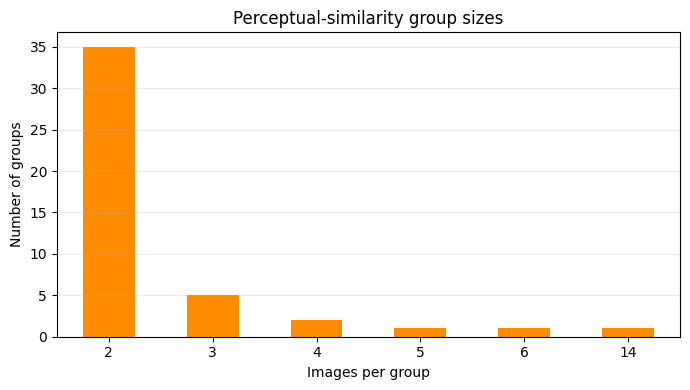

In [33]:
ax = near_duplicate_groups.value_counts().sort_index().plot.bar(figsize=(7, 4), color="darkorange")
ax.set(title="Perceptual-similarity group sizes", xlabel="Images per group", ylabel="Number of groups")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

similarity_0000: 14 visually similar images


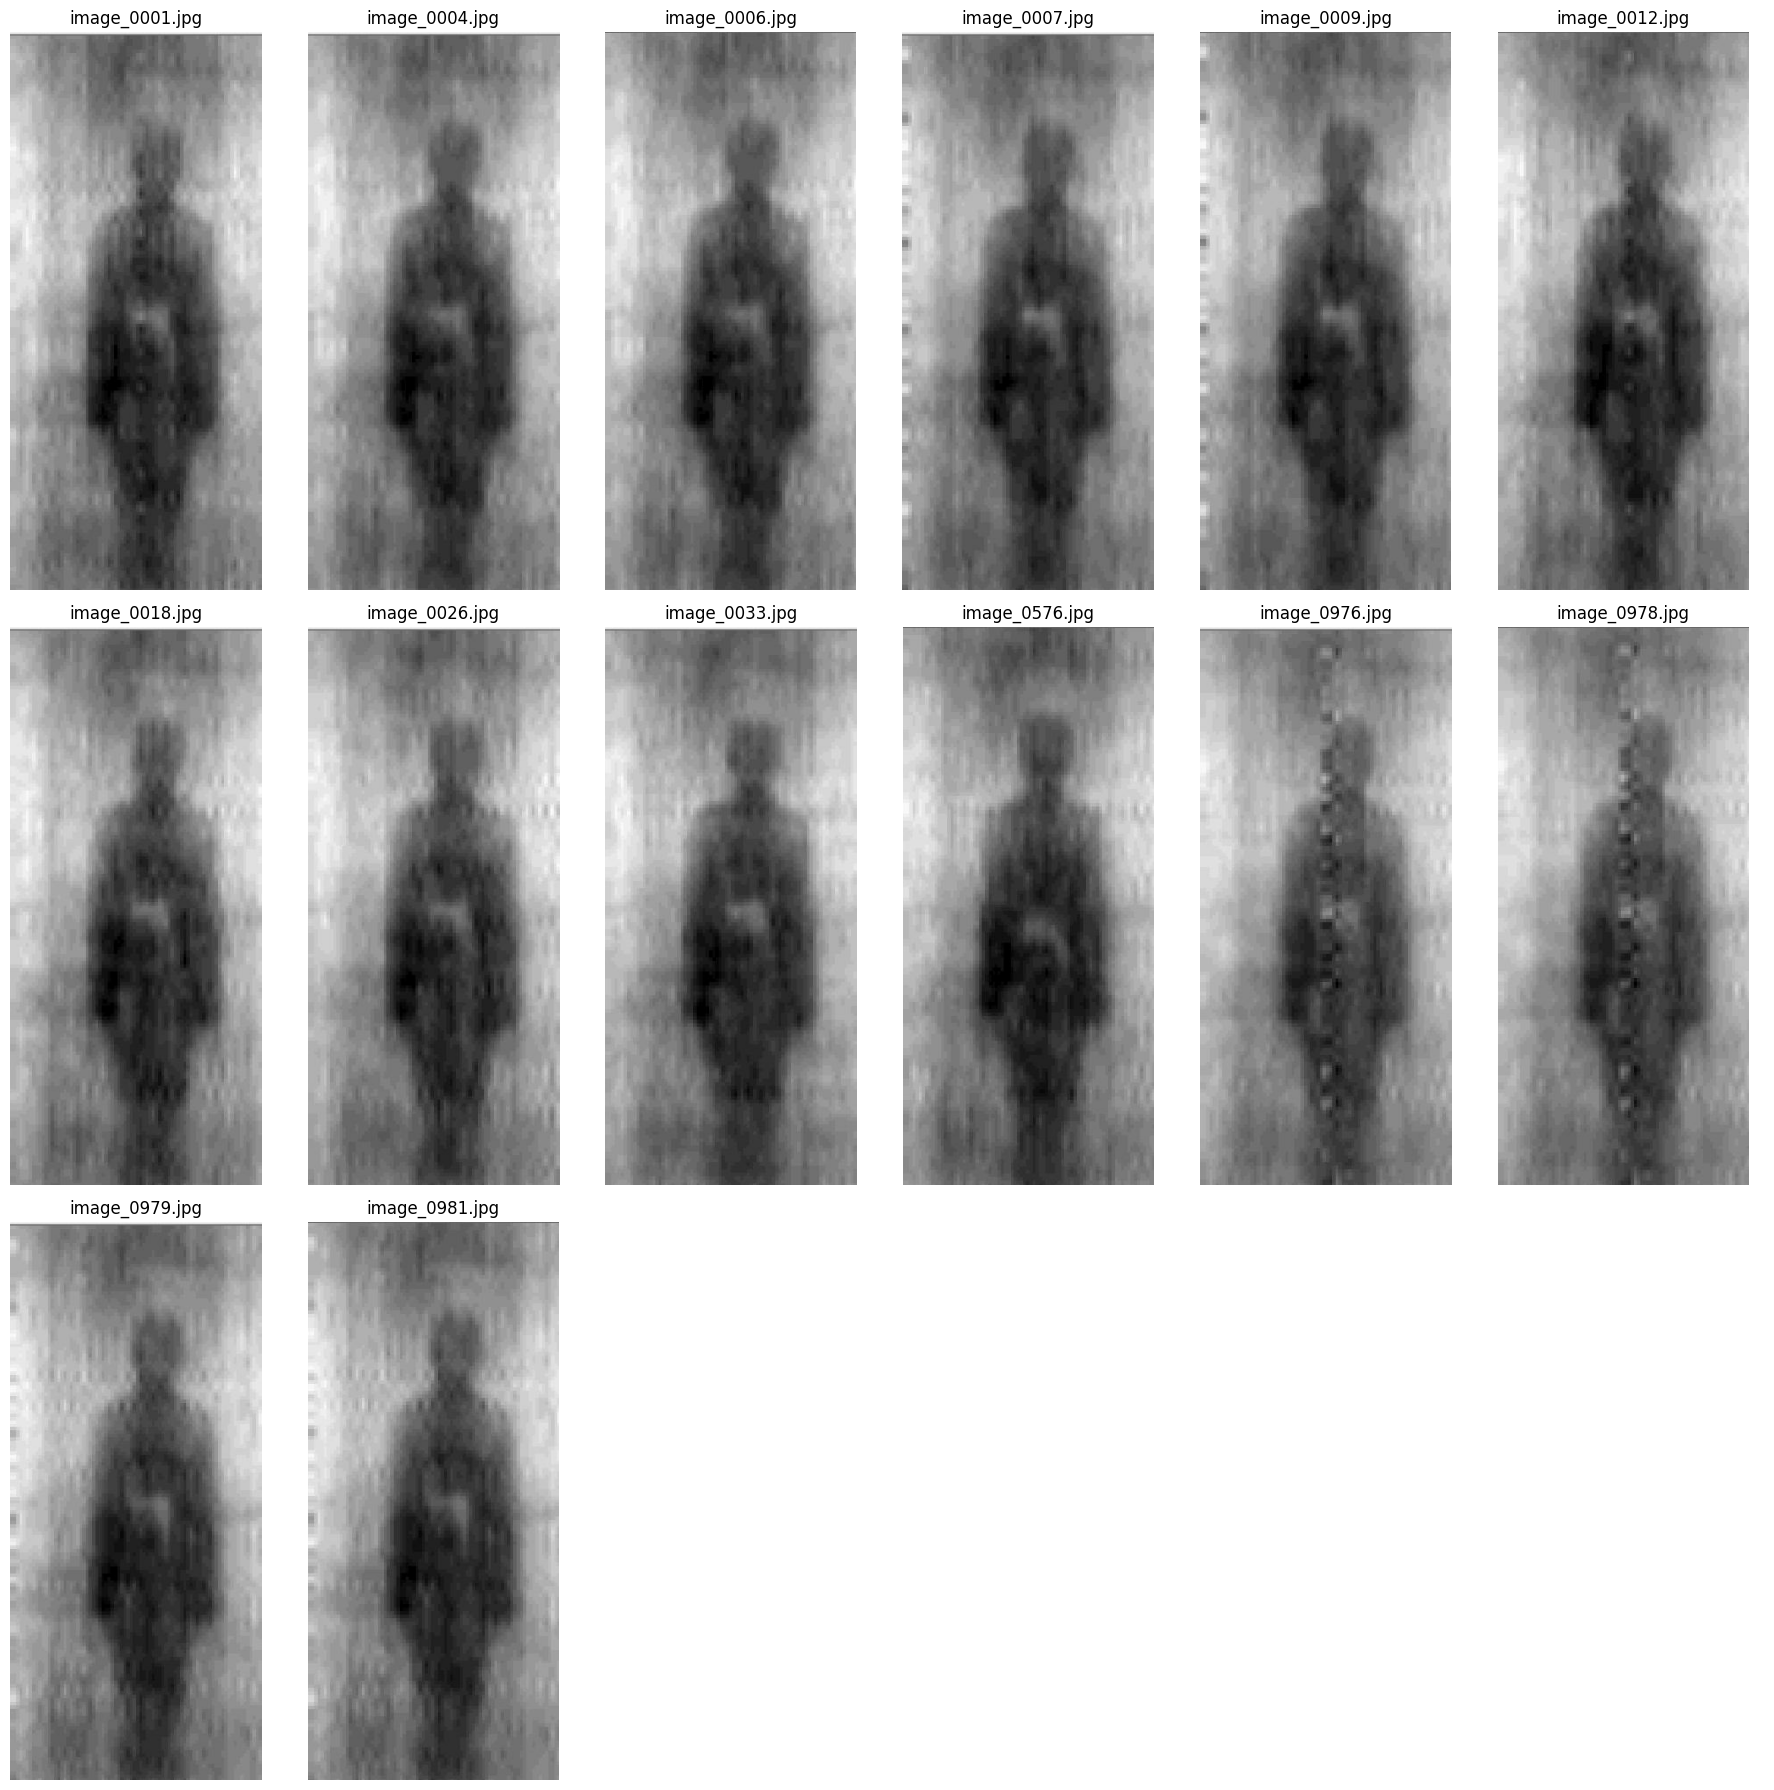

In [35]:
NEAR_DUPLICATE_REVIEW_GROUP = 1

group_id = near_duplicate_groups.index[NEAR_DUPLICATE_REVIEW_GROUP - 1]
group_images = training_images.loc[
    training_images["similarity_group"] == group_id, "image_name"
].tolist()
print(f"{group_id}: {len(group_images)} visually similar images")
show_images(group_images, columns=min(6, len(group_images)))

## 9. Create an 75/15/15 leakage-safe split

- Visually similar images remain in the same split

In [36]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
training_images["fold"] = -1

for fold, (_, indices) in enumerate(splitter.split(
    training_images, training_images["has_gun"], training_images["similarity_group"]
)):
    training_images.loc[training_images.index[indices], "fold"] = fold

training_images["split"] = "train"
training_images.loc[training_images["fold"].isin([0, 1, 2]), "split"] = "val"
training_images.loc[training_images["fold"].isin([3, 4, 5]), "split"] = "test"


split_statistics = training_images.groupby("split").agg(
    images=("image_name", "size"),
    gun_positive=("has_gun", "sum"),
    similarity_groups=("similarity_group", "nunique"),
).reindex(["train", "val", "test"])

split_statistics["gun_negative"] = split_statistics["images"] - split_statistics["gun_positive"]
display(split_statistics)

,images,gun_positive,similarity_groups,gun_negative
split,,,,
train,792,416,750,376
val,171,90,149,81
test,169,90,160,79


## 10. Convert the data to YOLO format

Each image receives a label file containing `class_id x_center y_center width height`. Coordinates are normalised, gun is class `0`, and negative images receive empty files.

In [37]:
from shutil import copy2

OUTPUT_ROOT = DATASET_ROOT.parent / "processed"
boxes_by_image = {name: boxes for name, boxes in gun_annotations.groupby("image_name")}

for split in ("train", "val", "test"):
    image_folder = OUTPUT_ROOT / "images" / split
    label_folder = OUTPUT_ROOT / "labels" / split
    image_folder.mkdir(parents=True, exist_ok=True)
    label_folder.mkdir(parents=True, exist_ok=True)

    for old_file in [*image_folder.glob("*"), *label_folder.glob("*")]:
        old_file.unlink()

    for image in training_images[training_images["split"] == split].itertuples(index=False):
        copy2(image.image_path, image_folder / image.image_name)
        boxes = boxes_by_image.get(image.image_name, pd.DataFrame())
        lines = [
            f"0 {(box.xmin + box.xmax) / (2 * box.width):.6f} "
            f"{(box.ymin + box.ymax) / (2 * box.height):.6f} "
            f"{(box.xmax - box.xmin) / box.width:.6f} "
            f"{(box.ymax - box.ymin) / box.height:.6f}"
            for box in boxes.itertuples(index=False)
        ]
        (label_folder / f"{Path(image.image_name).stem}.txt").write_text("\n".join(lines))

manifest_columns = ["image_name", "split", "has_gun", "similarity_group", "sha256"]
training_images[manifest_columns].to_csv(OUTPUT_ROOT / "split_manifest.csv", index=False)

dataset_yaml = f'''path: "{OUTPUT_ROOT.resolve().as_posix()}"
train: images/train
val: images/val
test: images/test
names:
  0: gun
'''
(OUTPUT_ROOT / "dataset.yaml").write_text(dataset_yaml, encoding="utf-8")
print(f"YOLO dataset created at: {OUTPUT_ROOT.resolve()}")

YOLO dataset created at: C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed


In [60]:
SKIP_ALL_EXPERIMENTS = False
RUN_EXPERIMENT_1 = True   # YOLOv8-Nano baseline
RUN_EXPERIMENT_2 = True   # YOLO11-Nano
RUN_EXPERIMENT_3 = True   # YOLOv8-Small
RUN_EXPERIMENT_4 = True   # YOLOv8-Medium
RUN_EXPERIMENT_5 = True   # YOLO26-Nano
RUN_EXPERIMENT_6 = True   # YOLO26-Small
RUN_EXPERIMENT_7 = True   # YOLO26-Medium
RUN_REPEATABILITY_EXPERIMENT = True

if SKIP_ALL_EXPERIMENTS:
    RUN_EXPERIMENT_1 = RUN_EXPERIMENT_2 = RUN_EXPERIMENT_3 = RUN_EXPERIMENT_4 = RUN_EXPERIMENT_5 = RUN_EXPERIMENT_6 = RUN_EXPERIMENT_7 = RUN_REPEATABILITY_EXPERIMENT = False

In [62]:
from time import perf_counter
from ultralytics import YOLO

RESULTS_ROOT = (DATASET_ROOT.parent / "results").resolve()

def run_experiment(weights, folder, batch=-1, seed=SEED):
    start = perf_counter()
    YOLO(weights).train(
        data=str(OUTPUT_ROOT / "dataset.yaml"), epochs=100, imgsz=640, batch=batch,
        device=0, cache=True, amp=True, patience=15, seed=seed,
        project=str(RESULTS_ROOT / folder), name="train", exist_ok=True,
        verbose=True, plots=False,
    )
    print(f"Training time: {(perf_counter() - start) / 60:.1f} minutes")
    return RESULTS_ROOT / folder / "train" / "weights" / "best.pt"

## 11. Train the YOLOv8-Nano baseline

Fine-tune the COCO-pretrained YOLOv8-Nano detector (about 3 million parameters) for the single gun class.

### Baseline settings

- 100 epochs with 15-epoch early stopping
- 640 x 640 images
- GPU 0, automatic batch size, RAM cache and mixed precision
- Seed 42 and default YOLO augmentation

Outputs are stored in `CWD/results/yolov8n_baseline`.

In [40]:
if RUN_EXPERIMENT_1:
    run_experiment("yolov8n.pt", "yolov8n_baseline")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Baseline validation results

Evaluate `best.pt` on validation data using precision, recall, mAP50, mAP50-95 and inference time. Keep the test set untouched.

In [41]:
if RUN_EXPERIMENT_1:
    results_dir = RESULTS_ROOT / "yolov8n_baseline"
    best_baseline = YOLO(results_dir / "train" / "weights" / "best.pt")
    metrics = best_baseline.val(
        data=str(OUTPUT_ROOT / "dataset.yaml"), split="val",
        project=str(results_dir), name="val", exist_ok=True,
        plots=True, conf=0.31,
    )

    for plot in (results_dir / "train").glob("val_batch*.jpg"):
        plot.unlink()

    print(f"Precision:     {metrics.box.mp:.3f}")
    print(f"Recall:        {metrics.box.mr:.3f}")
    print(f"mAP50:         {metrics.box.map50:.3f}")
    print(f"mAP50-95:      {metrics.box.map:.3f}")
    print(f"Inference:     {metrics.speed['inference']:.2f} ms/image")

Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 47.621.7 MB/s, size: 17.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\labels\val.cache... 171 images, 81 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 171/171 71.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 18.4it/s 0.6s.2s
                   all        171         90      0.937      0.922      0.958      0.502
Speed: 0.6ms preprocess, 1.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\yolov8n_baseline\val
Precision:     0.937
Reca

## 12. YOLOv8-Nano baseline error analysis

- **True positive:** a prediction matched to one ground-truth gun.
- **False positive:** an unmatched prediction.
- **False negative:** an unmatched ground-truth gun.

Filter predictions by confidence, then match them one-to-one using IoU. Validation data only.

In [42]:
from ultralytics import YOLO

def read_yolo_boxes(label_path, width, height):
    boxes = []
    for line in label_path.read_text().splitlines():
        _, x, y, w, h = map(float, line.split())
        boxes.append([
            (x - w / 2) * width, (y - h / 2) * height,
            (x + w / 2) * width, (y + h / 2) * height,
        ])
    return np.array(boxes).reshape(-1, 4)

def match_boxes(ground_truth, predictions, scores, iou_threshold):
    matched, true_positive, false_positive = set(), [], []

    for pred_index in np.argsort(-scores):
        box = predictions[pred_index]
        top_left = np.maximum(ground_truth[:, :2], box[:2])
        bottom_right = np.minimum(ground_truth[:, 2:], box[2:])
        intersection = np.prod(np.clip(bottom_right - top_left, 0, None), axis=1)
        gt_area = np.prod(ground_truth[:, 2:] - ground_truth[:, :2], axis=1)
        box_area = np.prod(box[2:] - box[:2])
        ious = intersection / np.maximum(gt_area + box_area - intersection, 1e-9)
        available = [i for i in np.argsort(-ious) if i not in matched]
        gt_index = available[0] if available else None

        if gt_index is not None and ious[gt_index] >= iou_threshold:
            matched.add(gt_index)
            true_positive.append(pred_index)
        else:
            false_positive.append(pred_index)
    false_negative = [i for i in range(len(ground_truth)) if i not in matched]
    return true_positive, false_positive, false_negative

def load_validation_data(model, image_dir, label_dir, min_confidence):
    image_paths = sorted(image_dir.glob("*.jpg"))
    results = model.predict(
        [str(path) for path in image_paths], conf=min_confidence,
        device=0, save=False, verbose=False,
    )

    data = {}
    for image_path, result in zip(image_paths, results):
        height, width = result.orig_shape
        label_path = label_dir / f"{image_path.stem}.txt"
        data[image_path.name] = (
            read_yolo_boxes(label_path, width, height),
            result.boxes.xyxy.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
        )
    return data

def evaluate_thresholds(data, confidence, iou):
    ground_truth = tp = fp = fn = 0
    missed_images, false_positive_images = [], []

    for image_name, (true_boxes, boxes, scores) in data.items():
        keep = scores >= confidence
        matches = match_boxes(true_boxes, boxes[keep], scores[keep], iou)
        image_tp, image_fp, image_fn = map(len, matches)
        ground_truth += len(true_boxes)
        tp += image_tp
        fp += image_fp
        fn += image_fn
        if image_fn:
            missed_images.append(image_name)
        if image_fp:
            false_positive_images.append(image_name)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    stats = dict(ground_truth=ground_truth, tp=tp, fp=fp, fn=fn, precision=precision, recall=recall, f1=f1)
    return stats, missed_images, false_positive_images

def plot_threshold_sweep(results, confidence_values, iou_values, confidence, iou):
    titles = {"Precision": "Fewer false alarms", "Recall": "Fewer missed guns", "F1": "Overall balance"}
    figure, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

    for axis, metric in zip(axes, titles):
        values = results.pivot(index="IoU", columns="Confidence", values=metric)
        values = values.reindex(index=iou_values, columns=confidence_values)
        heatmap = axis.imshow(values, vmin=0, vmax=1, cmap="RdYlGn", origin="lower", aspect="auto")
        for row in range(len(iou_values)):
            for column in range(len(confidence_values)):
                axis.text(column, row, f"{values.iloc[row, column]:.2f}", ha="center", va="center")
        axis.add_patch(Rectangle((confidence_values.index(confidence) - 0.5, iou_values.index(iou) - 0.5), 1, 1, fill=False, color="blue", linewidth=3))
        axis.set(title=f"{titles[metric]} ({metric})", xlabel="Confidence threshold")
        axis.set_xticks(range(len(confidence_values)), confidence_values)
        axis.set_yticks(range(len(iou_values)), iou_values)

    axes[0].set_ylabel("IoU threshold")
    figure.colorbar(heatmap, ax=axes, label="Score")
    plt.show()

def show_false_positives(image_names, data, image_dir, confidence, iou):
    if not image_names:
        print("None")
        return

    columns = min(3, len(image_names))
    rows = int(np.ceil(len(image_names) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(6 * columns, 6 * rows), squeeze=False)

    for axis, image_name in zip(axes.flat, image_names):
        ground_truth, boxes, scores = data[image_name]
        keep = scores >= confidence
        boxes, scores = boxes[keep], scores[keep]
        _, false_positives, _ = match_boxes(ground_truth, boxes, scores, iou)
        axis.imshow(Image.open(image_dir / image_name))

        for index in false_positives:
            x1, y1, x2, y2 = boxes[index]
            axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", linewidth=1))
            axis.text(
                x1, y1, f"gun {scores[index]:.2f}", color="white", fontsize=12,
                bbox=dict(facecolor="red", alpha=0.6, edgecolor="none", pad=1),
            )
        axis.set_title(image_name)

    for axis in axes.flat:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

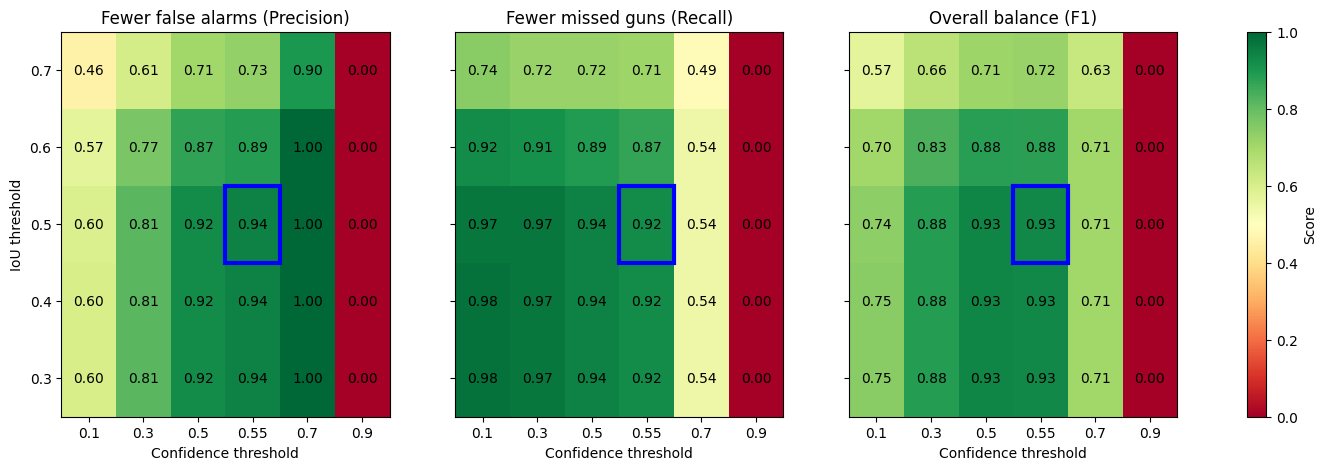

Chosen thresholds: confidence 0.55, IoU 0.50
True positives:    83/90 ground-truth guns
Missed guns:       7
False positives:   5
Precision: 0.943 / Recall: 0.922 / F1: 0.933


In [43]:
CONF_THRESHOLD = 0.55
IOU_THRESHOLD = 0.50
CONFIDENCE_SWEEP = sorted({0.10, 0.30, 0.50, 0.70, 0.90, CONF_THRESHOLD})
IOU_SWEEP = sorted({0.30, 0.40, 0.50, 0.60, 0.70, IOU_THRESHOLD})

BASELINE_DIR = (DATASET_ROOT.parent / "results" / "yolov8n_baseline").resolve()
VAL_IMAGE_DIR = OUTPUT_ROOT / "images" / "val"
VAL_LABEL_DIR = OUTPUT_ROOT / "labels" / "val"

model = YOLO(BASELINE_DIR / "train" / "weights" / "best.pt")
validation_data = load_validation_data(model, VAL_IMAGE_DIR, VAL_LABEL_DIR, min(CONFIDENCE_SWEEP))

sweep_rows = []
for iou in IOU_SWEEP:
    for confidence in CONFIDENCE_SWEEP:
        stats, _, _ = evaluate_thresholds(validation_data, confidence, iou)
        sweep_rows.append([confidence, iou, stats["precision"], stats["recall"], stats["f1"]])

sweep_results = pd.DataFrame(sweep_rows, columns=["Confidence", "IoU", "Precision", "Recall", "F1"])
plot_threshold_sweep(sweep_results, CONFIDENCE_SWEEP, IOU_SWEEP, CONF_THRESHOLD, IOU_THRESHOLD)

chosen, missed_images, false_positive_images = evaluate_thresholds(
    validation_data, CONF_THRESHOLD, IOU_THRESHOLD
)
print(f"Chosen thresholds: confidence {CONF_THRESHOLD:.2f}, IoU {IOU_THRESHOLD:.2f}")
print(f"True positives:    {chosen['tp']}/{chosen['ground_truth']} ground-truth guns")
print(f"Missed guns:       {chosen['fn']}")
print(f"False positives:   {chosen['fp']}")
print(f"Precision: {chosen['precision']:.3f} / Recall: {chosen['recall']:.3f} / F1: {chosen['f1']:.3f}")

Missed-gun images


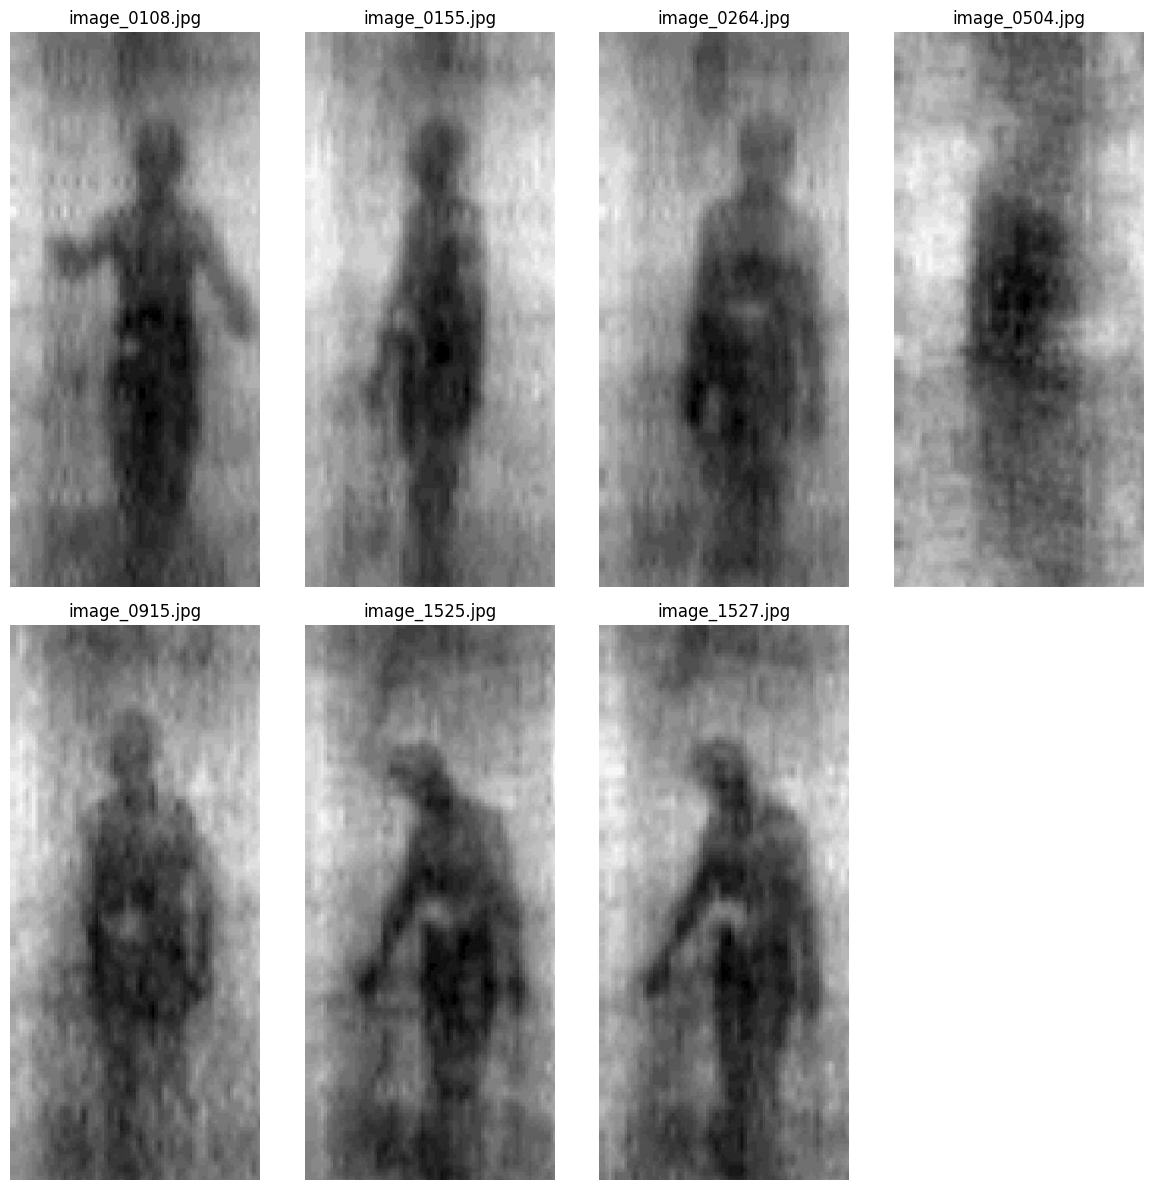

False-positive images


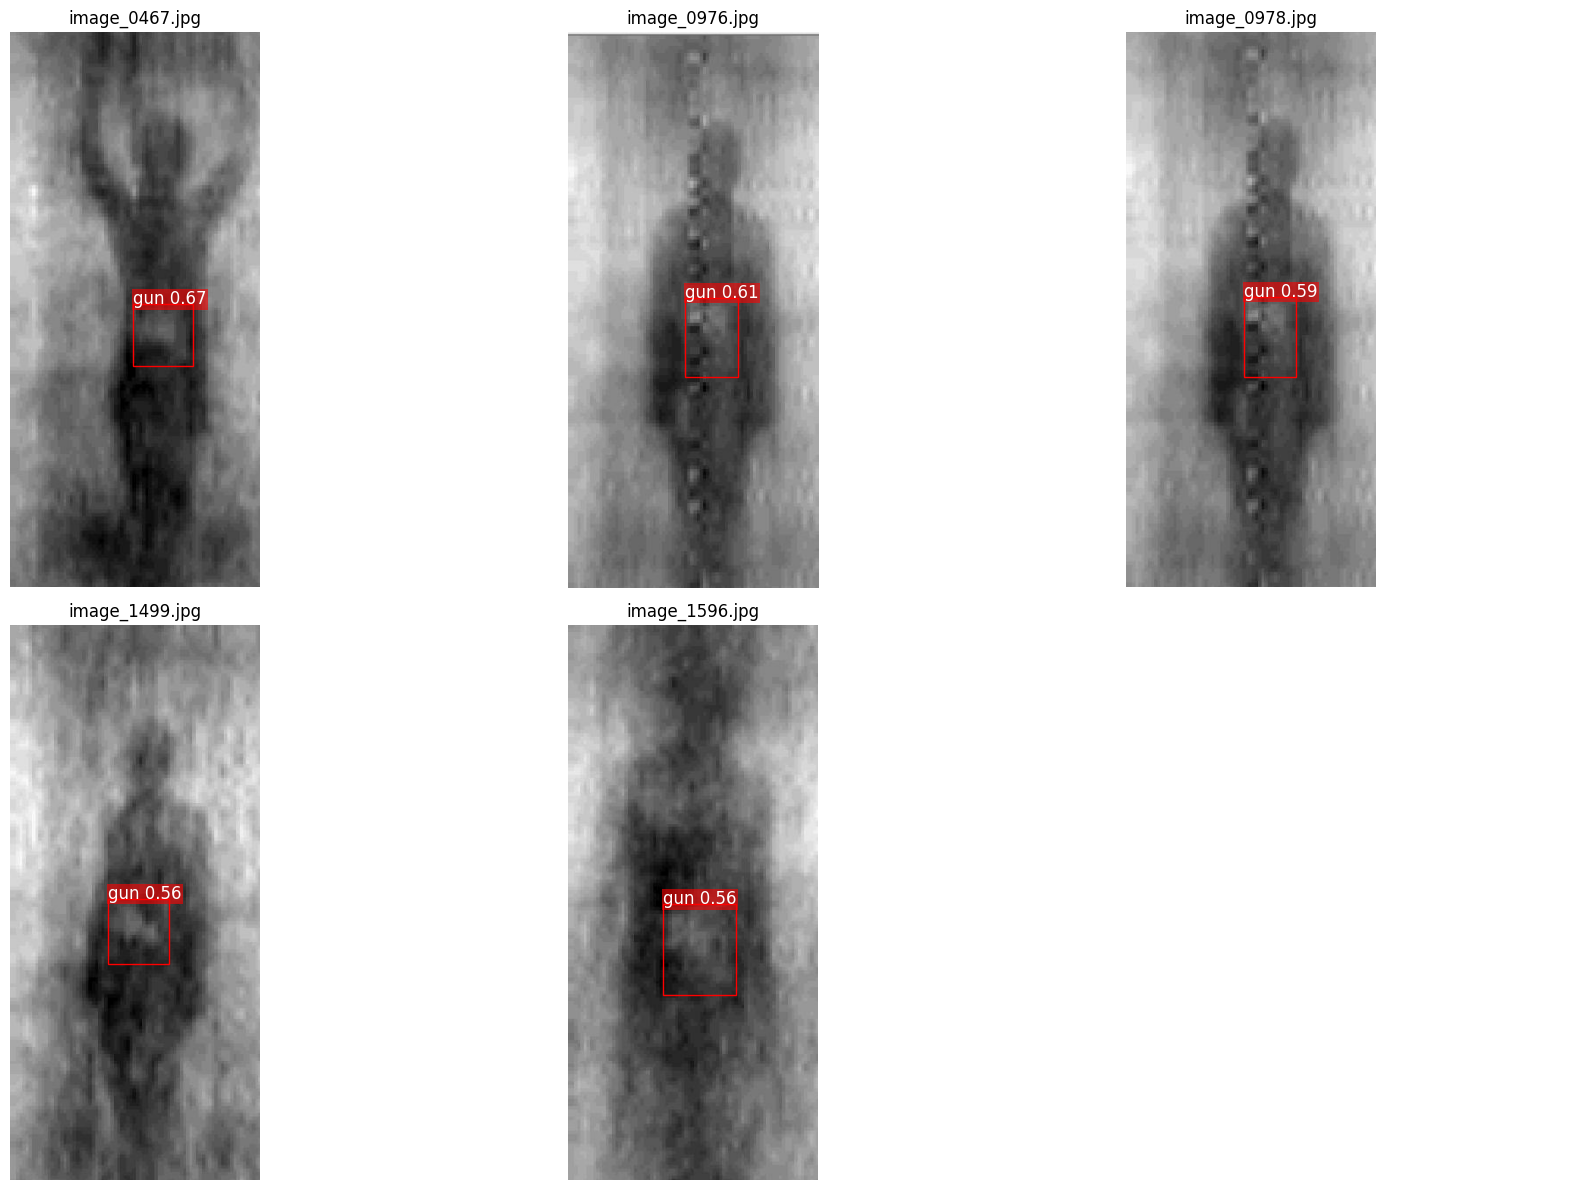

In [44]:
print("Missed-gun images")
show_images(missed_images)

print("False-positive images")
show_false_positives(
    false_positive_images, validation_data, VAL_IMAGE_DIR,
    CONF_THRESHOLD, IOU_THRESHOLD,
)

## 13. Additional detector experiments

Train six pretrained detectors under the same conditions as the YOLOv8-Nano baseline.

### Experiment 2: YOLO11-Nano

A newer lightweight architecture with fewer parameters than the baseline.

In [45]:
if RUN_EXPERIMENT_2:
    run_experiment("yolo11n.pt", "yolo11n")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Experiment 3: YOLOv8-Small

A moderate increase in capacity that may remain suitable for edge deployment.

In [46]:
if RUN_EXPERIMENT_3:
    run_experiment("yolov8s.pt", "yolov8s")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Experiment 4: YOLOv8-Medium

A heavier model used to test whether much greater capacity substantially improves detection.

In [47]:
if RUN_EXPERIMENT_4:
    run_experiment("yolov8m.pt", "yolov8m")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Experiment 5: YOLO26-Nano

A newer lightweight detector for comparison with the existing Nano models.

In [55]:
if RUN_EXPERIMENT_5:
    run_experiment("yolo26n.pt", "yolo26n")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Experiment 6: YOLO26-Small

A higher-capacity YOLO26 model that may still suit edge deployment.

In [56]:
if RUN_EXPERIMENT_6:
    run_experiment("yolo26s.pt", "yolo26s")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### Experiment 7: YOLO26-Medium

A heavier YOLO26 model used to measure the benefit of additional capacity.

In [57]:
if RUN_EXPERIMENT_7:
    run_experiment("yolo26m.pt", "yolo26m")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

## 14. Validation and edge-deployment comparison

- **AP50:** gun detection quality at IoU 0.50
- **mAP50-95:** stricter overall detection and localisation quality
- **Precision:** resistance to false alarms
- **Recall:** ability to avoid missing guns
- **Parameters:** model size and complexity
- **p95 latency:** a realistic upper-end response time
- **Peak GPU memory:** relative inference hardware demand

All accuracy metrics use the validation split. Latency is end-to-end, batch-one inference over the validation images.

In [58]:
import torch

def compare_detector(experiment, folder):
    checkpoint = RESULTS_ROOT / folder / "train" / "weights" / "best.pt"
    model = YOLO(checkpoint)
    metrics = model.val(
        data=str(OUTPUT_ROOT / "dataset.yaml"), split="val", device=0,
        project=str(RESULTS_ROOT / folder), name="val", exist_ok=True,
        plots=False, verbose=False,
    )

    images = sorted((OUTPUT_ROOT / "images" / "val").glob("*.jpg"))
    for _ in range(5):
        model.predict(str(images[0]), imgsz=640, device=0, verbose=False)

    torch.cuda.reset_peak_memory_stats()
    latency = []
    for image in images:
        torch.cuda.synchronize()
        start = perf_counter()
        model.predict(str(image), imgsz=640, device=0, verbose=False)
        torch.cuda.synchronize()
        latency.append((perf_counter() - start) * 1000)

    return {
        "Experiment": experiment, "AP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Precision": metrics.box.mp, "Recall": metrics.box.mr,
        "Parameters (M)": sum(p.numel() for p in model.model.parameters()) / 1e6,
        "p95 latency (ms)": np.percentile(latency, 95),
        "Peak GPU memory (MB)": torch.cuda.max_memory_allocated() / 1024**2,
    }

In [59]:
MODEL_RUNS = {
    "Experiment 1 - YOLOv8-Nano": "yolov8n_baseline",
    "Experiment 2 - YOLO11-Nano": "yolo11n",
    "Experiment 3 - YOLOv8-Small": "yolov8s",
    "Experiment 4 - YOLOv8-Medium": "yolov8m",
    "Experiment 5 - YOLO26-Nano": "yolo26n",
    "Experiment 6 - YOLO26-Small": "yolo26s",
    "Experiment 7 - YOLO26-Medium": "yolo26m",
}

rows = [
    compare_detector(experiment, folder)
    for experiment, folder in MODEL_RUNS.items()
    if (RESULTS_ROOT / folder / "train" / "weights" / "best.pt").exists()
]
results_table = pd.DataFrame(rows).set_index("Experiment")
results_table.to_csv(RESULTS_ROOT / "model_comparison.csv")
display(results_table.style.format({
    "AP50": "{:.3f}", "mAP50-95": "{:.3f}",
    "Precision": "{:.3f}", "Recall": "{:.3f}",
    "Parameters (M)": "{:.2f}", "p95 latency (ms)": "{:.2f}",
    "Peak GPU memory (MB)": "{:.1f}",
}).highlight_max(
    subset=["AP50", "mAP50-95", "Precision", "Recall"], color="green"
).highlight_min(
    subset=["Parameters (M)", "p95 latency (ms)", "Peak GPU memory (MB)"], color="green"
))

Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 0.00.0 ms, read: 35.45.7 MB/s, size: 17.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\labels\val.cache... 171 images, 81 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 171/171 71.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 19.8it/s 0.6s0.1s
                   all        171         90      0.937      0.922      0.972      0.513
Speed: 0.5ms preprocess, 1.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
YOLO11n summary

,AP50,mAP50-95,Precision,Recall,Parameters (M),p95 latency (ms),Peak GPU memory (MB)
Experiment,,,,,,,
Experiment 1 - YOLOv8-Nano,0.972,0.513,0.937,0.922,3.01,11.72,536.2
Experiment 2 - YOLO11-Nano,0.961,0.535,0.934,0.911,2.58,9.73,547.5
Experiment 3 - YOLOv8-Small,0.965,0.534,0.942,0.904,11.13,6.99,598.8
Experiment 4 - YOLOv8-Medium,0.971,0.534,0.920,0.933,25.84,8.80,655.9
Experiment 5 - YOLO26-Nano,0.966,0.508,0.923,0.938,2.38,8.26,662.0
Experiment 6 - YOLO26-Small,0.960,0.520,0.976,0.894,9.47,7.99,664.5
Experiment 7 - YOLO26-Medium,0.939,0.519,0.940,0.889,20.35,8.38,748.8


## 15. Three-seed repeatability comparison

Train YOLO11-Nano and YOLO26-Nano three times with the same fixed batch size. Report validation mean and standard deviation; keep the test split untouched.

In [63]:
REPEAT_BATCH_SIZE = 32
REPEAT_SEEDS = [42, 43, 44]
REPEAT_MODELS = {"YOLO11-Nano": ("yolo11n.pt", "yolo11n"), "YOLO26-Nano": ("yolo26n.pt", "yolo26n")}
REPEAT_METRICS = ["AP50", "mAP50-95", "Precision", "Recall"]
REPEAT_ROOT = Path("repeatability")

if RUN_REPEATABILITY_EXPERIMENT:
    rows = []
    for model_name, (weights, model_folder) in REPEAT_MODELS.items():
        for seed in REPEAT_SEEDS:
            folder = REPEAT_ROOT / model_folder / f"seed_{seed}"
            checkpoint = run_experiment(weights, folder, REPEAT_BATCH_SIZE, seed)
            metrics = YOLO(checkpoint).val(
                data=str(OUTPUT_ROOT / "dataset.yaml"), split="val", device=0,
                project=str(RESULTS_ROOT / folder), name="val", exist_ok=True,
                plots=False, verbose=False,
            )
            rows.append({
                "Model": model_name, "Seed": seed,
                "AP50": metrics.box.map50, "mAP50-95": metrics.box.map,
                "Precision": metrics.box.mp, "Recall": metrics.box.mr,
            })

    repeat_results = pd.DataFrame(rows)
    repeat_summary = repeat_results.groupby("Model")[REPEAT_METRICS].agg(["mean", "std"])
    output_folder = RESULTS_ROOT / REPEAT_ROOT
    output_folder.mkdir(parents=True, exist_ok=True)
    repeat_results.to_csv(output_folder / "runs.csv", index=False)
    repeat_summary.to_csv(output_folder / "summary.csv")
    display(repeat_summary.style.format("{:.3f}"))
else:
    print("Repeatability experiment skipped.")

New https://pypi.org/project/ultralytics/8.4.118 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.115  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m